In [229]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from secomml.data_loader import load_secom
from secomml.data_eda import profile

sys.path.extend(['../src'])

## Brief data check

In [230]:
df, dl, dd = load_secom("../data/raw/secom.zip")
df

,pass,timestamp,x0,x1,x2,x3,x4,x5,x6,x7,...,x580,x581,x582,x583,x584,x585,x586,x587,x588,x589
0,-1,2008-07-19 11:55:00,3030.93,2564.0,2187.7333,1411.1265,1.3602,100,97.6133,0.1242,...,<NA>,<NA>,0.5005,0.0118,0.0035,2.363,<NA>,<NA>,<NA>,<NA>
1,-1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100,102.3433,0.1247,...,0.006,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.006,208.2045
2,1,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100,95.4878,0.1241,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,-1,2008-07-19 14:43:00,2988.72,2479.9,2199.0333,909.7926,1.3204,100,104.2367,0.1217,...,0.0044,73.8432,0.499,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,-1,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.52,1.5334,100,100.3967,0.1235,...,<NA>,<NA>,0.48,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1562,-1,2008-10-16 15:13:00,2899.41,2464.36,2179.7333,3085.3781,1.4843,100,82.2467,0.1248,...,0.0047,203.172,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.172
1563,-1,2008-10-16 20:49:00,3052.31,2522.55,2198.5667,1124.6595,0.8763,100,98.4689,0.1205,...,<NA>,<NA>,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.172
1564,-1,2008-10-17 05:26:00,2978.81,2379.78,2206.3,1110.4967,0.8236,100,99.4122,0.1208,...,0.0025,43.5231,0.4987,0.0153,0.0041,3.059,0.0197,0.0086,0.0025,43.5231
1565,-1,2008-10-17 06:01:00,2894.92,2532.01,2177.0333,1183.7287,1.5726,100,98.7978,0.1213,...,0.0075,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941


In [231]:
n = df.shape[0]
p = df.shape[1]
df.shape

(1567, 592)

In [ ]:
df_profile = profile(df)
df_profile.to_excel("../output/secom_data_profile.xlsx", index=False)
df_profile

AttributeError: 'DataFrame' object has no attribute 'write_xlsx'

## Types

In [233]:
# Type statistics
print(df_profile['type'].value_counts().to_string())

type
Float64           466
Int64             125
datetime64[us]      1


### pass column as bool

In [234]:
# Convert the 'pass' column to boolean type
df01 = df.copy()
df01['pass'] = df01['pass'].map(lambda x: 1 if x == -1 else 0)
print(df01['pass'].value_counts())
df01['pass'] = df01['pass'].astype(pd.BooleanDtype())
print(df01['pass'].value_counts())
print(df01['pass'].dtypes)

pass
1    1463
0     104
Name: count, dtype: Int64
pass
True     1463
False     104
Name: count, dtype: Int64
boolean


In [235]:
#%%writefile -a ../src/secomml/data_convert_types.py
def convert_pass_to_boolean(df, column_name='pass'):
    """
    Convert a `pass` column in the DataFrame to boolean type.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    column_name (str): The name of the column to convert.
    
    Returns:
    pd.DataFrame: A new DataFrame with the specified column converted to boolean type.
    """
    df_copy = df.copy()
    df_copy[column_name] = df_copy[column_name].map(lambda x: 1 if x == -1 else 0)
    df_copy[column_name] = df_copy[column_name].astype(pd.BooleanDtype())
    return df_copy

In [236]:
df = convert_pass_to_boolean(df, 'pass')

In [237]:
# Check
df['pass'].value_counts()

pass
True     1463
False     104
Name: count, dtype: Int64

### Integers

In [238]:
# Checking what columns can be converted to smaller integer types based on their min and max values
df_int64 = df.select_dtypes(include=["Int64"])
print(df_int64.agg(['count','var','min','max']).T)
# Care only about columns with non-zero variance, these with zero variance are not useful and will be dropped later.
df_int64_with_var_not_zero = df_int64.loc[:, df_int64.var() > 0]
df_int64_with_var_not_zero.agg(['count','var','min','max']).T

       count  var    min    max
x5    1553.0  0.0  100.0  100.0
x13   1564.0  0.0    0.0    0.0
x42   1566.0  0.0   70.0   70.0
x49   1566.0  0.0    1.0    1.0
x52   1566.0  0.0    0.0    0.0
...      ...  ...    ...    ...
x534  1558.0  0.0    0.0    0.0
x535  1558.0  0.0    0.0    0.0
x536  1558.0  0.0    0.0    0.0
x537  1558.0  0.0    0.0    0.0
x538  1558.0  0.0    0.0    0.0

[124 rows x 4 columns]


,count,var,min,max
x55,1563.0,663.027339,2801.0,2936.0
x135,1562.0,3311.384124,58.0,994.0
x159,1565.0,966373.582005,0.0,7791.0
x160,1565.0,330404.91323,0.0,4170.0
x161,1565.0,17971198.660494,0.0,37943.0
x162,1565.0,42949270.795767,0.0,36871.0
x206,1561.0,0.002562,0.0,2.0
x478,1561.0,25.6246,0.0,200.0


In [239]:
# Check types capacity
for dtype in [pd.UInt8Dtype(), pd.UInt16Dtype(), pd.UInt32Dtype(), pd.UInt64Dtype()]:
    info = np.iinfo(dtype.type)
    print(f"{dtype}: min={info.min}, max={info.max}")
for dtype in [pd.Int8Dtype(), pd.Int16Dtype(), pd.Int32Dtype(), pd.Int64Dtype()]:
    info = np.iinfo(dtype.type)
    print(f"{dtype}: min={info.min}, max={info.max}")

UInt8: min=0, max=255
UInt16: min=0, max=65535
UInt32: min=0, max=4294967295
UInt64: min=0, max=18446744073709551615
Int8: min=-128, max=127
Int16: min=-32768, max=32767
Int32: min=-2147483648, max=2147483647
Int64: min=-9223372036854775808, max=9223372036854775807


In [240]:
# Map columns to types based on their min and max.
conversion_table = {'UInt8':['x206','x478'], 'UInt16':['x55','x135','x159','x160','x161','x162']}

In [241]:
#%%writefile -a ../src/secomml/data_convert_types.py
def convert_to_integer_type(df, column_names, target_dtype):
    """
    Convert specified columns in the DataFrame to a given integer type.
    
    Parameters:
    df (pd.DataFrame): The input DataFrame.
    column_names (list): List of column names to convert.
    target_dtype (str): The target integer type (e.g., 'Int8', 'Int16', 'Int32', 'Int64').
    
    Returns:
    pd.DataFrame: A new DataFrame with the specified columns converted to the target integer type.
    """
    df_copy = df.copy()
    for col in column_names:
        df_copy[col] = df_copy[col].astype(target_dtype)
    return df_copy

In [242]:
# Check conversion
for dtype, columns in conversion_table.items():
    df = convert_to_integer_type(df, columns, dtype)
df[df_int64_with_var_not_zero.columns].info()

<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   x55     1563 non-null   UInt16
 1   x135    1562 non-null   UInt16
 2   x159    1565 non-null   UInt16
 3   x160    1565 non-null   UInt16
 4   x161    1565 non-null   UInt16
 5   x162    1565 non-null   UInt16
 6   x206    1561 non-null   UInt8 
 7   x478    1561 non-null   UInt8 
dtypes: UInt16(6), UInt8(2)
memory usage: 33.8 KB


### TODO

add proper rules to Pandera/GE for converted types

## Variance

In [243]:
xnames = df.columns.str.startswith("x")

In [244]:
# select only columns with zero variance
xvar = df.loc[:, xnames]
xvar_with_zero_variance = xvar.loc[:, xvar.var().eq(0)]
var0_names = xvar_with_zero_variance.columns
print(f'var=0 columns: {var0_names.shape[0]}')
print('Example of var=0 columns:')
xvar_with_zero_variance.head()

var=0 columns: 116
Example of var=0 columns:


,x5,x13,x42,x49,x52,x69,x97,x141,x149,x178,...,x529,x530,x531,x532,x533,x534,x535,x536,x537,x538
0,100,0,70,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,100,0,70,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,100,0,70,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,100,0,70,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,100,0,70,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [245]:
#%%writefile -a ../src/secomml/data_cleaning.py
def drop_zero_variance_columns(df):
    """
    Drop columns with zero variance from the DataFrame.
    
    Parameters:
    df (pd.DataFrame): The input DataFrame.
    
    Returns:
    pd.DataFrame: A new DataFrame with zero variance columns dropped.
    List: A list of column names that were dropped.
    """
    df_copy = df.copy()
    xnames = df_copy.columns.str.startswith("x")
    xvar = df_copy.loc[:, xnames]
    zero_variance_columns = xvar.loc[:, xvar.var() == 0].columns
    return df_copy.drop(columns=zero_variance_columns), zero_variance_columns.tolist()
    

In [246]:
df, dropped_columns = drop_zero_variance_columns(df)

In [247]:
# Check dropped columns were removed
kept = [col for col in dropped_columns if col in df.columns]
if (len(kept) > 0):
    print("Error: Some dropped columns are still present in the DataFrame.")
else:
    print("Dropped columns successfully removed from the DataFrame.")

Dropped columns successfully removed from the DataFrame.


## Missing

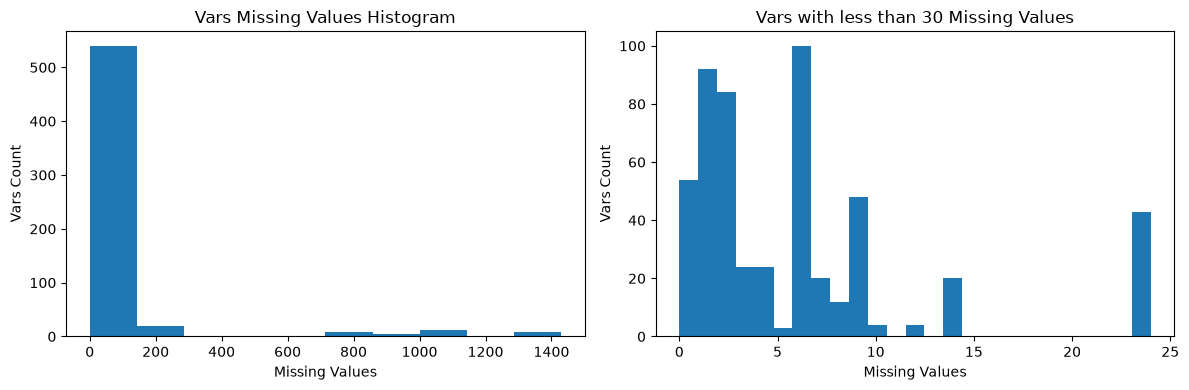

In [175]:
# statistics of missing values
missing = df.isna().sum()
# plot
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
missing.plot(kind='hist', ax=ax[0], bins=10, title='Vars Missing Values Histogram', xlabel='Missing Values', ylabel='Vars Count')
missing30 = missing[missing < 30]
missing30.plot(kind='hist', ax=ax[1], bins=25, title='Vars with less than 30 Missing Values', xlabel='Missing Values', ylabel='Vars Count')
plt.tight_layout()
plt.show()